# XL430 pair

Apply the marked equation, then change one gain at a time.
Click the red **Stop** button shown by each trial to end the loop and turn torque off.
Plots appear automatically. The final `await` lets Jupyter receive button clicks.

## Connect

Set the serial port, baud and motor ID(s). `PWM_LIMIT=0.80` allows up to 80% PWM output.

In [5]:
import dxl_utils as dxl

PWM_LIMIT = 0.80  # duty fraction; 0.80 = 80%
lab = dxl.connect("COM7", station="A1", baud=1_000_000,
                  leader=1, follower=2, pwm_limit=PWM_LIMIT, stop_button=True, demo=False)

A1: COM7; torque off. Gains/output use duty fraction. Run one experiment cell.


## $u_F=k_p(q_L-q_F)+k_d(\dot q_L-\dot q_F)$

The follower pulls towards the leader position; the velocity term damps their relative motion. Commands are PWM duty fractions. Raise the position gain to reduce tracking error, then add damping and compare overshoot.

**Change:** `kp`: 0.06 → 0.12 → 0.18; `kd`: 0 → 0.008. Then `T`: 0.001 → 0.005 → 0.010.

**Delay:** `delay_ms=0` delays outgoing commands; try 10, 50 and 100 ms with gains unchanged.

Button(button_style='danger', description='Stop', icon='stop', style=ButtonStyle())

1_unilateral: target 100 Hz (T=10 ms). Click the Stop button above; torque off and plots follow.
Stop button: stopped normally; torque off.
Requested 100 Hz (10 ms); achieved 100 Hz. Period mean/p99/max: 10.000/10.520/13.499 ms; jitter SD: 0.271 ms; skipped periods: 0; work over budget: 0 cycles.
1_unilateral {'tracking_rmse_rad': 0.5341163542657372, 'max_error_rad': 1.583068173097982}


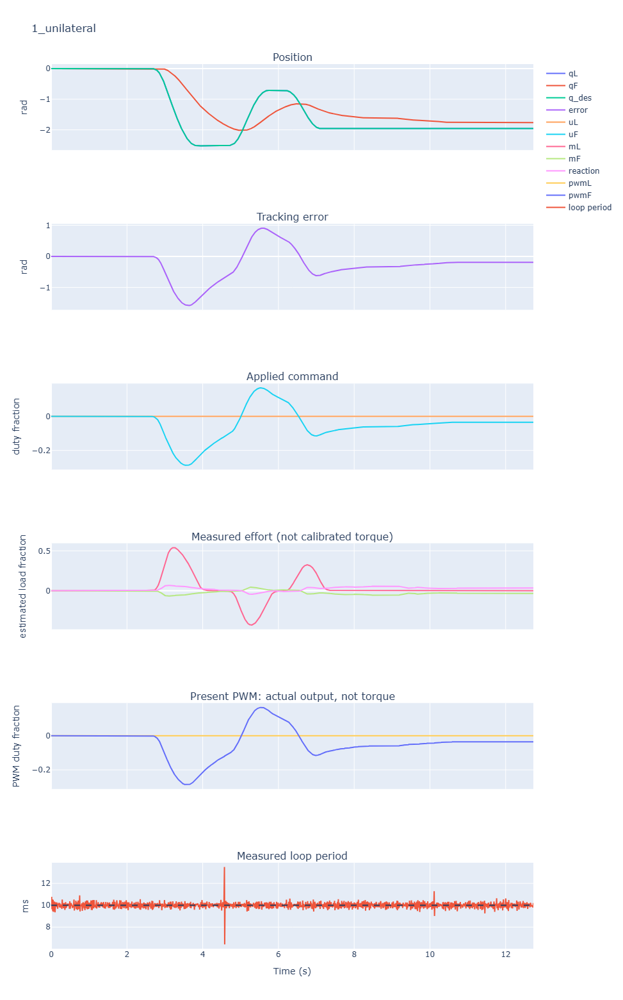

In [6]:
T = 0.010  # seconds; then compare 0.005 and 0.010
kp, kd = 0.18, 0.008
delay_ms = 0
delay = dxl.Delay(samples=round(delay_ms/1000/T))
with lab.run("1_unilateral", leader="off", dt=T) as run:
    while run.active:
        L, F = run.read()
        uF = kp * (L.q - F.q) + kd * (L.v - F.v)
        uF, = delay(uF)
        run.write(follower=uF)
        await run.wait_async()

## $u_L=-\beta\,\mathrm{PWM}_F$

The follower tracks hand position using its internal position controller. Reflect its actual PWM output to the leader: resistance should increase when the follower presses against an obstacle. PWM is an effort proxy, not a calibrated contact-force measurement.

**Change:** `beta`: 0.25 → 0.5 → 1.0. Compare free motion and contact.

**Delay:** `delay_ms=0` delays outgoing commands; try 10, 50 and 100 ms with gains unchanged.

Button(button_style='danger', description='Stop', icon='stop', style=ButtonStyle())

2_effort_feedback: target 1000 Hz (T=1 ms). Click the Stop button above; torque off and plots follow.
Stop button: stopped normally; torque off.
Requested 1000 Hz (1 ms); achieved 233 Hz. Period mean/p99/max: 4.283/5.176/8.451 ms; jitter SD: 0.440 ms; skipped periods: 50891; work over budget: 15502 cycles.
2_effort_feedback {'tracking_rmse_rad': 0.07577835863578126, 'max_error_rad': 0.4535469862848778}


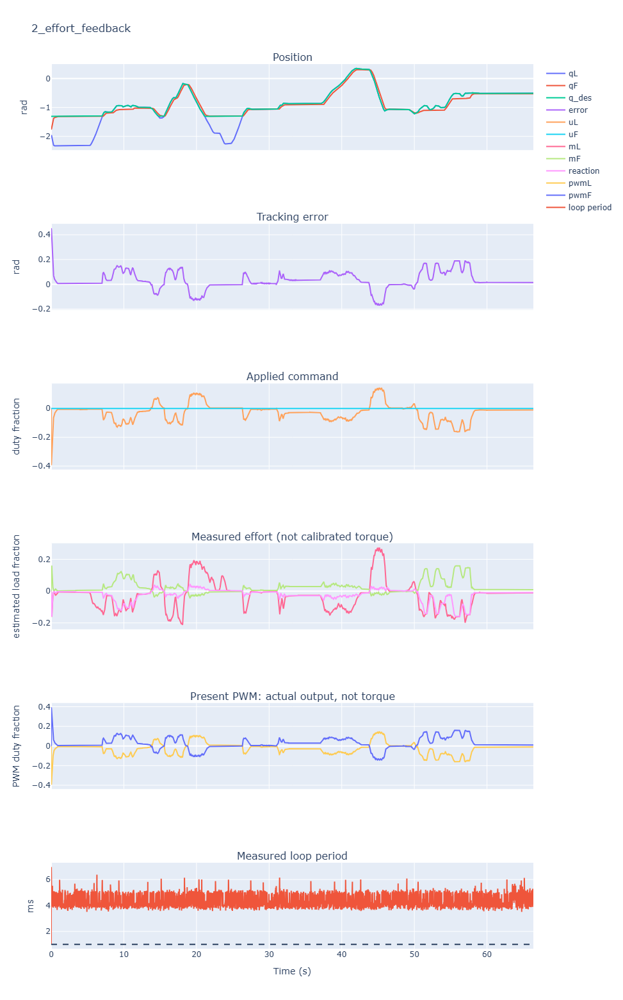

In [7]:
T = 0.001
beta = 1
delay_ms = 0.0
delay = dxl.Delay(samples=round(delay_ms/1000/T))
with lab.run("2_effort_feedback", leader="effort", follower="position", position_kp=150, dt=T) as run:
    while run.active:
        L, F = run.read()
        uL = -beta * F.pwm
        uL, qsend = delay(uL, L.q)
        run.write(leader=uL, follower_position=qsend)
        await run.wait_async()

## Admittance: $\dot q_c=k_a(q_L-q_c)/b_a$

Push the leader away from its commanded position to make both motors move. Hand deflection acts as an input-effort proxy; this is not measured-force admittance. Both motors use powered position control, and the commanded motion is bounded to ±0.52 rad (30°).

**Change:** `damping`: 4 → 2 → 1. Lower damping gives more motion for the same push. Keep `gain` fixed; then compare `T`: 0.001 → 0.005 → 0.010.

**Delay:** `delay_ms=0` delays outgoing commands; try 10, 50 and 100 ms with gains unchanged.

Button(button_style='danger', description='Stop', icon='stop', style=ButtonStyle())

3_admittance: target 1000 Hz (T=1 ms). Click the Stop button above; torque off and plots follow.
Stop button: stopped normally; torque off.
Requested 1000 Hz (1 ms); achieved 249 Hz. Period mean/p99/max: 4.016/4.930/7.923 ms; jitter SD: 0.153 ms; skipped periods: 22723; work over budget: 7535 cycles.
3_admittance_4 {'tracking_rmse_rad': 0.0822758544607648, 'max_error_rad': 0.6795340019403149}


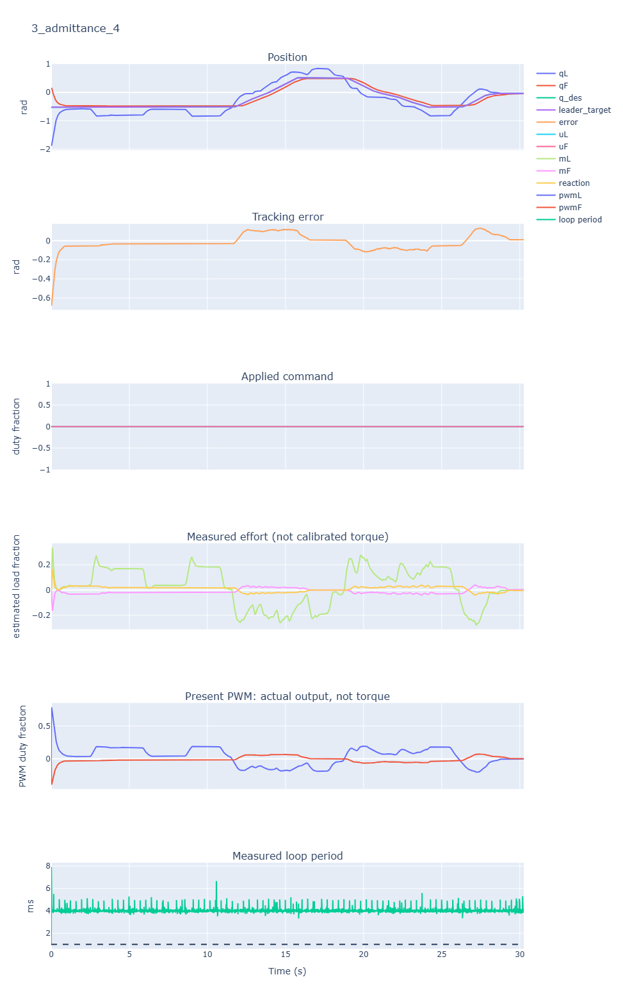

In [11]:
T = 0.001
gain, damping, limit = 1.0, 1.0, 0.52
delay_ms = 0.0
delay = dxl.Delay(samples=round(delay_ms/1000/T))
with lab.run("3_admittance", leader="position", follower="position", position_kp=100, dt=T) as run:
    qcmd = dxl.clip(run.leader.q, limit)
    while run.active:
        L, F = run.read()
        velocity = gain * (L.q - qcmd)/damping
        qcmd = dxl.clip(qcmd + run.dt*velocity, limit)
        qsend, = delay(qcmd)
        run.write(leader_position=qsend, follower_position=qsend, target=qcmd)
        await run.wait_async()

## Disconnect

In [ ]:
lab.close()